# Month 2 Project: AI-Powered Sentiment Analysis System
**Objective:** Build an end-to-end NLP pipeline to classify customer reviews into **Positive**, **Negative**, or **Neutral** sentiment using classical machine learning and TF-IDF representations.

---
### Workflow Summary:
1. **Step 1:** Data Understanding & Cleaning
2. **Step 2:** Exploratory Data Analysis (EDA)
3. **Step 3:** Text Preprocessing & Justification
4. **Step 4:** Feature Extraction (TF-IDF vs. BoW)
5. **Step 5:** Supervised Model Training & Comparison
6. **Step 6:** Model Evaluation (Confusion Matrix, Metrics, ROC/AUC)
7. **Step 7:** Cross-Validation & Hyperparameter Tuning (GridSearchCV)
8. **Step 8:** Pipeline Assembly & Serialization
9. **Step 9:** Testing & Validation on Benchmark Customer Reviews


In [1]:
# Step 0: Library Imports
import os
import re
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_extraction import text
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

# Configure plot styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('../images', exist_ok=True)
os.makedirs('../models', exist_ok=True)
print('Libraries imported successfully.')


Libraries imported successfully.


## Step 1 — Data Understanding & Cleaning
We load the customer review dataset from `../data/reviews.csv`.  
Each record contains:
- `review_id`: Unique identifier
- `review_text`: Raw textual review (primary model input)
- `sentiment`: Ground truth target (`Positive`, `Negative`, `Neutral`)
- `category`: Product or service sector
- `source`: Platform of feedback origin


In [2]:
# Load dataset
df = pd.read_csv('../data/reviews.csv')

print('Dataset Shape:', df.shape)
print('\nFirst 5 Records:')
display(df.head())

print('\nDataset Information:')
print(df.info())

print('\nMissing Values Check:')
print(df.isnull().sum())


Dataset Shape: (10092, 5)

First 5 Records:


,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10092 entries, 0 to 10091
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    10092 non-null  int64 
 1   review_text  10092 non-null  object
 2   sentiment    10092 non-null  object
 3   category     10092 non-null  object
 4   source       10092 non-null  object
dtypes: int64(1), object(4)
memory usage: 394.3+ KB
None

Missing Values Check:
review_id      0
review_text    0
sentiment      0
category       0
source         0
dtype: int64


## Step 2 — Exploratory Data Analysis (EDA)
In this step, we analyze:
1. Class balance across sentiment targets
2. Distribution of review lengths
3. Breakdown of reviews across product categories and sources


Sentiment Distribution:
 sentiment
Negative    3371
Positive    3363
Neutral     3358
Name: count, dtype: int64


C:\Users\ghosh\AppData\Local\Temp\ipykernel_23320\1351108090.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sentiment', order=['Positive', 'Negative', 'Neutral'], palette=['#2ecc71', '#e74c3c', '#3498db'], ax=axes[0])
C:\Users\ghosh\AppData\Local\Temp\ipykernel_23320\1351108090.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='category', order=df['category'].value_counts().index, palette='Blues_r', ax=axes[1])


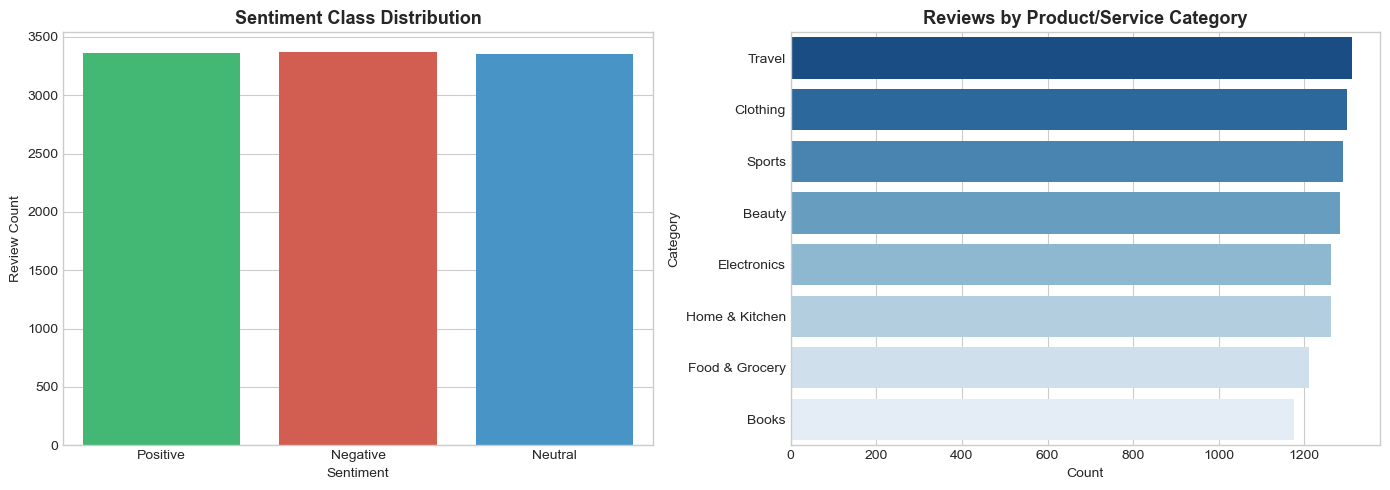

In [3]:
# 1. Sentiment Class Balance
sentiment_counts = df['sentiment'].value_counts()
print('Sentiment Distribution:\n', sentiment_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart of sentiments
sns.countplot(data=df, x='sentiment', order=['Positive', 'Negative', 'Neutral'], palette=['#2ecc71', '#e74c3c', '#3498db'], ax=axes[0])
axes[0].set_title('Sentiment Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Review Count')

# Category breakdown
sns.countplot(data=df, y='category', order=df['category'].value_counts().index, palette='Blues_r', ax=axes[1])
axes[1].set_title('Reviews by Product/Service Category', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Category')

plt.tight_layout()
plt.savefig('../images/sentiment_distribution.png', dpi=300)
plt.show()


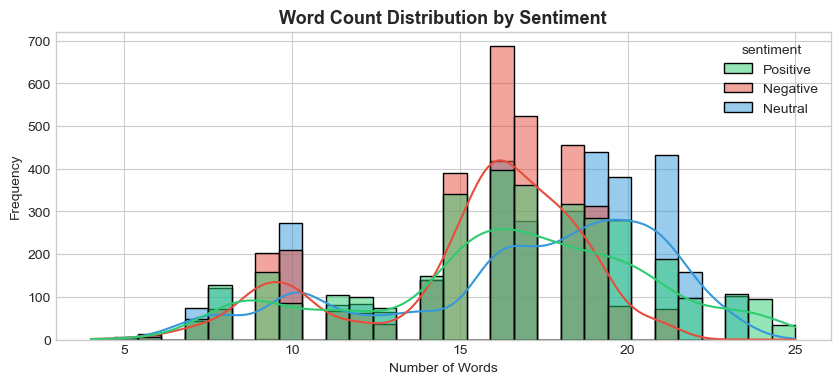

          word_count                                                    \
               count       mean       std  min   25%   50%   75%   max   
sentiment                                                                
Negative      3371.0  15.365470  3.373300  4.0  14.0  16.0  18.0  21.0   
Neutral       3358.0  16.877606  4.219290  4.0  14.0  18.0  20.0  23.0   
Positive      3363.0  16.394588  4.246963  5.0  14.0  17.0  19.0  25.0   

          char_length                                                          
                count       mean        std   min   25%    50%     75%    max  
sentiment                                                                      
Negative       3371.0  89.982201  20.200574  20.0  78.0   97.0  103.00  119.0  
Neutral        3358.0  96.841572  23.155030  37.0  87.0  102.0  112.75  136.0  
Positive       3363.0  95.747249  22.300535  32.0  88.0   99.0  109.00  134.0  


In [4]:
# 2. Review Length Characteristics
df['char_length'] = df['review_text'].apply(len)
df['word_count'] = df['review_text'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 4))
sns.histplot(data=df, x='word_count', hue='sentiment', bins=30, kde=True, palette=['#2ecc71', '#e74c3c', '#3498db'])
plt.title('Word Count Distribution by Sentiment', fontsize=13, fontweight='bold')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.savefig('../images/word_count_distribution.png', dpi=300)
plt.show()

print(df.groupby('sentiment')[['word_count', 'char_length']].describe())


## Step 3 — Text Preprocessing
Text preprocessing cleans and normalizes raw text so the feature extractor can focus on informative sentiment signals.

### Preprocessing Operations & Justification:
1. **Lowercasing**: Ensures identical words in different cases (e.g., `"Terrible"`, `"terrible"`, `"TERRIBLE"`) map to the same vocabulary token.
2. **URL Removal**: Hyperlinks (`http://...`, `www...`) provide no sentiment information and add noise to feature dimensions.
3. **Non-alphabetic Character Filtering**: Removes numbers, punctuation symbols, and special characters while preserving standard alphabetical tokens.
4. **Whitespace Normalization**: Compresses multi-space artifacts and trims leading/trailing spaces.
5. **Domain & Negation Aware Stopwords**: Retains critical negation words (`not`, `never`, `no`, `neither`, `dont`, `wont`) so phrases like `"not good"` are not stripped of negation.


In [5]:
# Preprocessing function
def clean_text(text: str) -> str:
    """Cleans raw review text for NLP feature extraction."""
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['review_text'].apply(clean_text)

# Domain stopwords preserving negations
custom_stops = list(text.ENGLISH_STOP_WORDS.difference({
    'not', 'no', 'never', 'nor', 'neither', 'hardly', 'barely', 'cannot', 'cant', 'wont', 'dont'
}))
custom_stops += ['product', 'item', 'purchase']

print('Sample of cleaned reviews:')
display(df[['review_text', 'clean_text', 'sentiment']].head(5))


Sample of cleaned reviews:


,review_text,clean_text,sentiment
0,This product exceeded my expectations in sever...,this product exceeded my expectations in sever...,Positive
1,The item is uncomfortable to use and poorly de...,the item is uncomfortable to use and poorly de...,Negative
2,The product comes with a charging adapter and ...,the product comes with a charging adapter and ...,Neutral
3,Customer support was slow and did not solve my...,customer support was slow and did not solve my...,Negative
4,"The design is simple, attractive, and comforta...",the design is simple attractive and comfortabl...,Positive


## Step 4 — Feature Extraction
We compare two classical NLP vectorization techniques:
1. **Bag of Words (`CountVectorizer`)**: Counts raw term frequencies. Does not downweight frequent uninformative words.
2. **TF-IDF (`TfidfVectorizer`)**: Downweights words that appear across all documents (high Document Frequency) and rewards discriminative sentiment words. Sublinear TF scaling (`1 + log(tf)`) dampens extreme term repetitions.

We use **n-grams `(1, 2)`** (unigrams + bigrams) to capture critical phrases such as `"not good"` and `"excellent quality"`.


In [6]:
# Feature Extraction Setup
X = df['clean_text']
y = df['sentiment']

# Stratified Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f'Training Samples: {len(X_train)} | Test Samples: {len(X_test)}')


Training Samples: 8073 | Test Samples: 2019


## Step 5 — Model Training & Comparison
We evaluate three supervised classification algorithms:
1. **Multinomial Naive Bayes (`MultinomialNB`)**: Probabilistic baseline for text classification.
2. **Linear Support Vector Classifier (`LinearSVC`)**: High-dimensional maximum margin classifier.
3. **Logistic Regression (`LogisticRegression`)**: Well-calibrated, interpretable model with native probability estimates.


In [7]:
# Model Comparison
candidate_models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Linear SVC': LinearSVC(random_state=42),
    'Logistic Regression': LogisticRegression(C=2.5, max_iter=2000, random_state=42)
}

comparison_results = []

for name, clf in candidate_models.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), stop_words=custom_stops, sublinear_tf=True)),
        ('classifier', clf)
    ])
    
    # Train
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
    
    comparison_results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision (Macro)': round(prec, 4),
        'Recall (Macro)': round(rec, 4),
        'F1-Score (Macro)': round(f1, 4)
    })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Multinomial Naive Bayes,0.9980,0.9980,0.9980,0.9980
1,Linear SVC,0.9985,0.9985,0.9985,0.9985
2,Logistic Regression,0.9985,0.9985,0.9985,0.9985


## Step 6 — Model Evaluation
We analyze detailed performance for the best-performing model:
- **Accuracy, Precision, Recall, and F1-score** per class
- **Confusion Matrix** heatmap
- **Multi-class ROC/AUC curves**


=== CLASSIFICATION REPORT ===

              precision    recall  f1-score   support

    Negative     0.9985    1.0000    0.9993       674
     Neutral     1.0000    0.9955    0.9978       672
    Positive     0.9970    1.0000    0.9985       673

    accuracy                         0.9985      2019
   macro avg     0.9985    0.9985    0.9985      2019
weighted avg     0.9985    0.9985    0.9985      2019



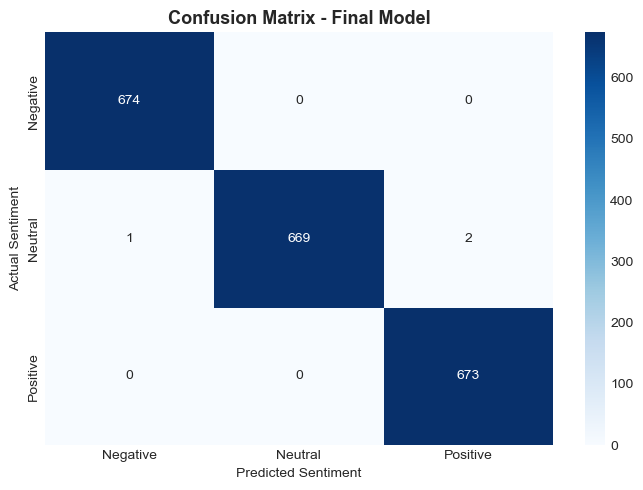

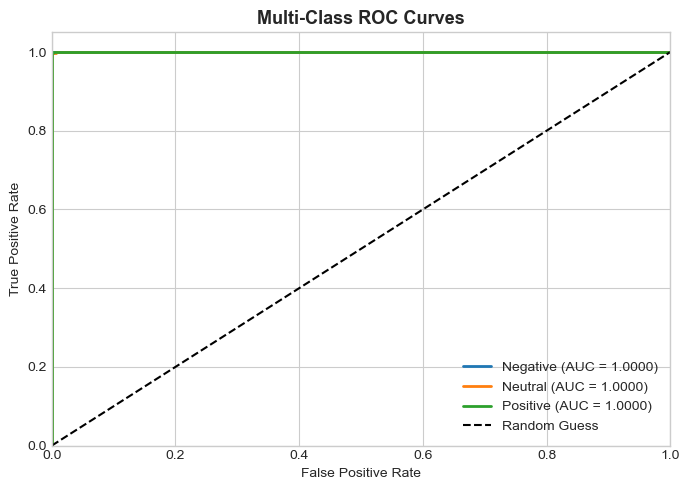

In [8]:
# Best Model Pipeline: Logistic Regression
best_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), stop_words=custom_stops, sublinear_tf=True)),
    ('classifier', LogisticRegression(C=2.5, max_iter=2000, random_state=42))
])

best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)

print('=== CLASSIFICATION REPORT ===\n')
print(classification_report(y_test, y_pred, digits=4))

# Confusion Matrix
labels = ['Negative', 'Neutral', 'Positive']
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix - Final Model', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.tight_layout()
plt.savefig('../images/confusion_matrix.png', dpi=300)
plt.show()

# Multi-class ROC & AUC
y_test_bin = label_binarize(y_test, classes=labels)
plt.figure(figsize=(7, 5))
for i, label in enumerate(labels):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{label} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC Curves', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../images/roc_auc_curve.png', dpi=300)
plt.show()


## Step 7 — Cross-Validation & Hyperparameter Tuning
To ensure our model does not overfit and generalizes effectively, we perform:
- 5-Fold Stratified Cross-Validation
- `GridSearchCV` hyperparameter tuning across `C` (regularization strength) and `ngram_range`.


In [9]:
# 1. 5-Fold Cross Validation
cv_scores = cross_val_score(best_pipeline, X, y, cv=5, scoring='accuracy', n_jobs=-1)
print(f'5-Fold Cross-Validation Scores: {cv_scores}')
print(f'Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})')

# 2. Hyperparameter Grid Search
param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'classifier__C': [1.0, 2.5, 5.0]
}

grid_search = GridSearchCV(
    best_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print('\nBest Hyperparameters Found:')
print(grid_search.best_params_)
print(f'Best Cross-Validation Score: {grid_search.best_score_:.4f}')

final_model = grid_search.best_estimator_


5-Fold Cross-Validation Scores: [1.         1.         1.         1.         0.97670961]
Mean CV Accuracy: 0.9953 (+/- 0.0093)
Fitting 3 folds for each of 6 candidates, totalling 18 fits



Best Hyperparameters Found:
{'classifier__C': 5.0, 'tfidf__ngram_range': (1, 1)}
Best Cross-Validation Score: 0.9979


## Step 8 — Pipeline & Model Serialization
We serialize the tuned pipeline to `../models/sentiment_pipeline.pkl`.  
This ensures the Streamlit web application can perform end-to-end inference without requiring model retraining.


In [10]:
# Serialize model pipeline
model_save_path = '../models/sentiment_pipeline.pkl'
joblib.dump(final_model, model_save_path)

print(f'Pipeline successfully serialized and saved to: {model_save_path}')
print(f'File size: {os.path.getsize(model_save_path) / 1024:.2f} KB')


Pipeline successfully serialized and saved to: ../models/sentiment_pipeline.pkl
File size: 18.84 KB


## Step 9 — Validation on Benchmark Test Reviews
We evaluate the serialized pipeline on benchmark review sentences covering edge cases, strong emotional expressions, and neutral phrases.


In [11]:
# Benchmark Test Cases
test_reviews = [
    'This product is terrible.',
    'I hate this product.',
    'This is the worst product ever.',
    'Very bad quality and completely disappointing.',
    'I am extremely unhappy with this purchase.',
    'The product is broken and completely useless.',
    'I absolutely loved this product.',
    'This product has excellent quality.',
    'The quality is okay, nothing special.'
]

print('=' * 65)
print('BENCHMARK EVALUATION RESULTS:')
print('=' * 65)

for review in test_reviews:
    cleaned = clean_text(review)
    prediction = final_model.predict([cleaned])[0]
    probs = final_model.predict_proba([cleaned])[0]
    prob_dict = {cls_name: round(prob, 4) for cls_name, prob in zip(final_model.classes_, probs)}
    
    print(f'Review: {review}')
    print(f'Prediction: {prediction}')
    print(f'Class Probabilities: {prob_dict}')
    print('-' * 65)


BENCHMARK EVALUATION RESULTS:
Review: This product is terrible.
Prediction: Negative
Class Probabilities: {'Negative': np.float64(0.7882), 'Neutral': np.float64(0.1448), 'Positive': np.float64(0.0669)}
-----------------------------------------------------------------
Review: I hate this product.
Prediction: Negative
Class Probabilities: {'Negative': np.float64(0.7921), 'Neutral': np.float64(0.1207), 'Positive': np.float64(0.0872)}
-----------------------------------------------------------------
Review: This is the worst product ever.
Prediction: Negative
Class Probabilities: {'Negative': np.float64(0.8027), 'Neutral': np.float64(0.1082), 'Positive': np.float64(0.0891)}
-----------------------------------------------------------------
Review: Very bad quality and completely disappointing.
Prediction: Negative
Class Probabilities: {'Negative': np.float64(0.9474), 'Neutral': np.float64(0.0238), 'Positive': np.float64(0.0288)}
--------------------------------------------------------------